# Computer Vision Lab - Assignment #01
**Ain Shams University | Mechatronics Engineering and Automation | CSE480/CSE482**

In this notebook I work through four image-processing tasks using the supplied images. I focus on the link between the arithmetic performed on the BGR arrays and what is visible in each result: a colour mask for the apples, weighted addition for the ghostly overlay, a smooth multiplication mask for the vignette, and channel permutations for the surreal-colour experiment. I keep the source files unchanged and save every generated stage under `results/`.

OpenCV loads colour data in **BGR** order, while Matplotlib expects **RGB** for display. I therefore keep the processing arrays in BGR and convert only the copies passed to plotting functions. The final section checks the output relationships numerically so that the explanations and figures refer to the same executed implementation.

**Public project repository:** [https://github.com/nadamorgan69-rgb/cse480-cse482-computer-vision-lab01](https://github.com/nadamorgan69-rgb/cse480-cse482-computer-vision-lab01)

In [1]:
from pathlib import Path
import hashlib
import json
import sys
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'images' / 'apple.png').is_file(), 'Open the notebook from its project folder.'
RESULTS = ROOT / 'results'
for task in range(1, 5):
    (RESULTS / f'task{task}').mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'font.size': 11, 'figure.facecolor': 'white'})
saved_arrays = {}
metrics = {}
checks = {}

def save_image(task, name, image):
    assert image.dtype == np.uint8 and image.size > 0
    assert image.ndim == 2 or (image.ndim == 3 and image.shape[2] == 3)
    path = RESULTS / f'task{task}' / f'{name}.png'
    assert cv2.imwrite(str(path), image), f'Could not save {path}'
    reloaded = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    assert reloaded is not None and np.array_equal(reloaded, image)
    saved_arrays[str(path.relative_to(ROOT))] = list(image.shape)

def show_grid(task, name, panels, columns=3, width=12, row_height=3.5):
    rows = (len(panels) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(width, row_height * rows), squeeze=False,
                             layout='constrained')
    for ax, (title, image) in zip(axes.flat, panels):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray', vmin=0, vmax=255, interpolation='nearest')
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
        ax.set_title(title, fontsize=11, pad=8)
        ax.set_aspect('equal')
        ax.axis('off')
    for ax in axes.flat[len(panels):]:
        ax.axis('off')
    path = RESULTS / f'task{task}' / f'{name}.png'
    fig.savefig(path, dpi=180, facecolor='white')
    assert path.is_file() and path.stat().st_size > 0
    plt.show()
    plt.close(fig)

images = {}
input_info = {}
expected_sizes = {'apple.png': (300, 300), 'blackCat.png': (500, 500),
                  'whiteCat.png': (500, 500), 'cameraman.jpg': (225, 225),
                  'marsrover.png': (480, 853), 'zebra.png': (313, 425)}
for name, expected_hw in expected_sizes.items():
    raw = cv2.imread(str(ROOT / 'images' / name), cv2.IMREAD_UNCHANGED)
    assert raw is not None, f'Invalid input: {name}'
    assert raw.shape == (*expected_hw, 3) and raw.dtype == np.uint8
    images[name] = cv2.imread(str(ROOT / 'images' / name), cv2.IMREAD_COLOR)
    input_info[name] = {'shape_HWC': list(raw.shape), 'dtype': str(raw.dtype),
                        'range': [int(raw.min()), int(raw.max())],
                        'sha256': hashlib.sha256((ROOT / 'images' / name).read_bytes()).hexdigest()}
original_copies = {name: image.copy() for name, image in images.items()}
display(Markdown('| Input | Height x width | Channels | Type | Range |\n'
                 '|---|---:|---:|---|---|\n' + '\n'.join(
    f'| {name} | {info["shape_HWC"][0]} x {info["shape_HWC"][1]} | 3 | {info["dtype"]} | {info["range"]} |'
    for name, info in input_info.items())))
print('OpenCV', cv2.__version__, '| NumPy', np.__version__, '| Matplotlib', matplotlib.__version__)

| Input | Height x width | Channels | Type | Range |
|---|---:|---:|---|---|
| apple.png | 300 x 300 | 3 | uint8 | [0, 249] |
| blackCat.png | 500 x 500 | 3 | uint8 | [4, 255] |
| whiteCat.png | 500 x 500 | 3 | uint8 | [0, 255] |
| cameraman.jpg | 225 x 225 | 3 | uint8 | [0, 255] |
| marsrover.png | 480 x 853 | 3 | uint8 | [0, 255] |
| zebra.png | 313 x 425 | 3 | uint8 | [0, 255] |

OpenCV 5.0.0 | NumPy 2.3.5 | Matplotlib 3.11.2


## Task 1 - Selective Colour Isolation

My aim is to keep red-dominant pixels in their original colour while showing the rest of the apple image in grayscale. I first create the grayscale version because it preserves brightness, edges, and fruit texture without retaining hue. I also split the original image into blue, green, and red planes. Since OpenCV returns them as B, G, R, the variable order is important.

A large red value by itself would also include bright yellow and orange pixels, so I use comparisons between the channels. The final condition is **R >= 70, R-G >= 30, R-B >= 25, and G-B <= 35**. The intensity floor removes very dark pixels, the two red-dominance gaps require red to be clearly stronger, and the green-blue limit reduces selection of the orange ribbon. I cast the channels to signed integers before subtraction because subtraction on `uint8` can wrap around and reverse the intended comparison.

Pixels that pass all four tests receive 255 in the binary mask and appear white; pixels that fail receive 0 and appear black. These thresholds are specific to this image. Tightening the red-dominance gaps would give fewer, purer red pixels, while relaxing them would keep more of the apple skins but also accept more yellow-orange areas. This is a pixel rule rather than semantic apple segmentation.

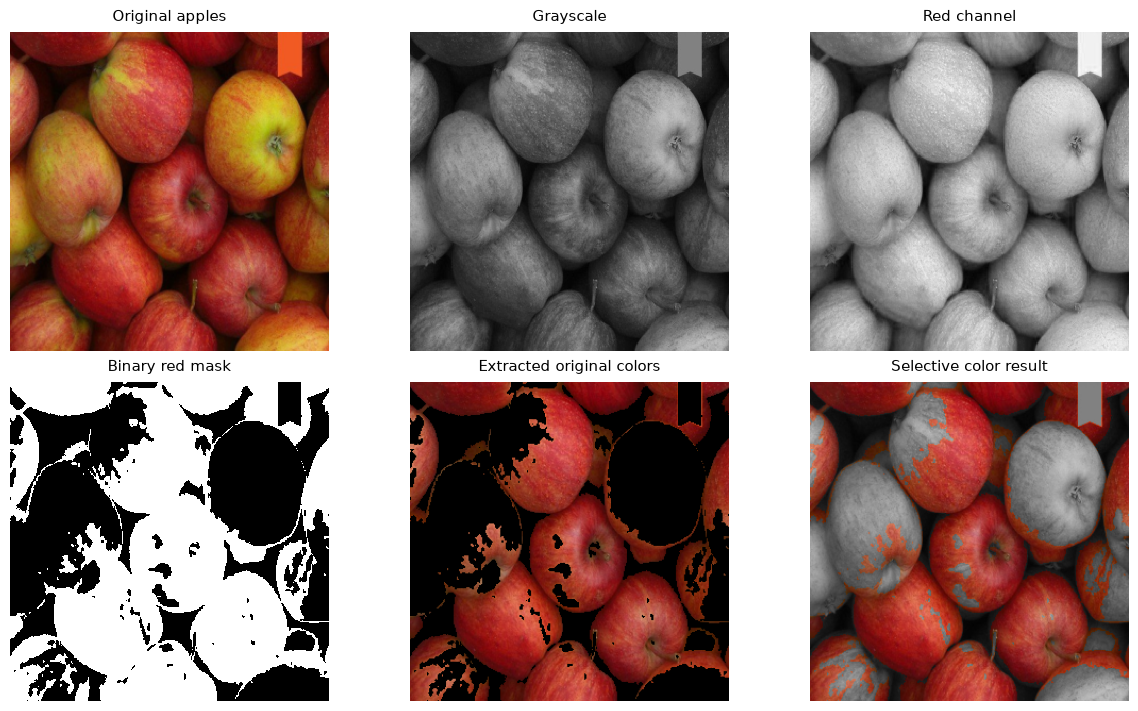

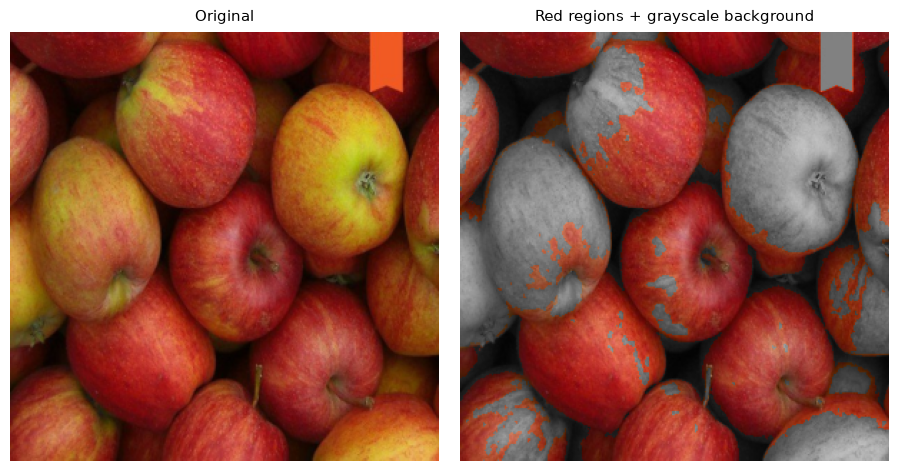

Selected 54.52% of pixels. Exact foreground/background composition: PASS.


In [2]:
apple = images['apple.png']
gray = cv2.cvtColor(apple, cv2.COLOR_BGR2GRAY)
blue, green, red = cv2.split(apple)
b, g, r = [channel.astype(np.int16) for channel in (blue, green, red)]
RED_MIN, RED_GREEN_GAP, RED_BLUE_GAP, MAX_GREEN_BLUE_GAP = 70, 30, 25, 35
selected = ((r >= RED_MIN) & (r - g >= RED_GREEN_GAP) &
            (r - b >= RED_BLUE_GAP) & (g - b <= MAX_GREEN_BLUE_GAP))
red_mask = selected.astype(np.uint8) * 255
colored_region = cv2.bitwise_and(apple, apple, mask=red_mask)
gray_bgr = cv2.cvtColor(gray, cv2.COLOR_GRAY2BGR)
inverse_mask = cv2.bitwise_not(red_mask)
gray_background = cv2.bitwise_and(gray_bgr, gray_bgr, mask=inverse_mask)
selective = cv2.bitwise_or(colored_region, gray_background)

assert red_mask.shape == apple.shape[:2] and red_mask.dtype == np.uint8
assert set(np.unique(red_mask)) == {0, 255}
assert np.array_equal(selective[selected], apple[selected])
assert np.array_equal(selective[~selected], gray_bgr[~selected])
assert np.all(selective[~selected, 0] == selective[~selected, 1])
assert np.all(selective[~selected, 1] == selective[~selected, 2])
assert np.all(colored_region[~selected] == 0)
metrics['task1'] = {'selected_percent': float(100 * selected.mean()),
                    'thresholds': [RED_MIN, RED_GREEN_GAP, RED_BLUE_GAP, MAX_GREEN_BLUE_GAP]}
for name, image in [('original', apple), ('grayscale', gray), ('red_channel', red),
                    ('red_mask', red_mask), ('colored_region', colored_region),
                    ('grayscale_background', gray_background), ('selective_color', selective)]:
    save_image(1, name, image)
show_grid(1, 'stages', [('Original apples', apple), ('Grayscale', gray), ('Red channel', red),
                      ('Binary red mask', red_mask), ('Extracted original colors', colored_region),
                      ('Selective color result', selective)])
show_grid(1, 'comparison', [('Original', apple), ('Red regions + grayscale background', selective)],
          columns=2, width=9, row_height=4.6)
checks['task1'] = 'PASS'
print(f'Selected {selected.mean():.2%} of pixels. Exact foreground/background composition: PASS.')

The binary mask selects **54.52%** of the image. I use `bitwise_and` with that mask to extract the selected original BGR pixels. I invert the mask and use it to extract the complementary pixels from the three-channel grayscale image. Because the two masks do not overlap, `bitwise_or` can join the colour and grayscale parts without adding their intensities.

In the stage figure, the central and lower red apples keep large areas of colour, while the yellow-green apples and highlights are mostly gray. The selection is visibly patchy inside several apples: local yellow mottling, bright reflections, stalks, and shadowed skin do not satisfy the same channel relationships as the red skin around them. Those gray holes are therefore consistent with the threshold logic rather than an error in the bitwise composition. A narrow red-dominant part of the ribbon is also retained even though it is not an apple. This is the main limitation of the method: it identifies pixels with a chosen colour signature, not complete objects with boundaries. Whole-apple detection would need spatial grouping, shape information, or an object segmentation method.

## Task 2 - Creating a Ghostly Overlay

`cv2.addWeighted()` combines values at matching pixel coordinates, so the inputs must have identical dimensions, compatible channel formats, and the same data type. The cameraman image is already **225 x 225**. The zebra is **425 x 313**, so I resize it proportionally to **225 x 166** and add 29 white rows above and 30 below. This keeps the complete zebra and avoids stretching it. Both prepared inputs are then 225 x 225, three-channel, `uint8` BGR arrays. They share a canvas, although the two unrelated scenes are not geometrically registered.

For every coordinate and channel, the operation is

**output = alpha x cameraman + beta x zebra + gamma**

with `gamma = 0` and `alpha + beta = 1`. Alpha is the numerical contribution of the cameraman pixel and beta is the contribution of the zebra pixel. For example, equal weights turn values 80 and 240 at the same location into approximately 160 after rounding. The weights therefore control which image contributes more strongly at every pixel, not a separate object-level transparency.

Original HWC: (225, 225, 3) (313, 425, 3)


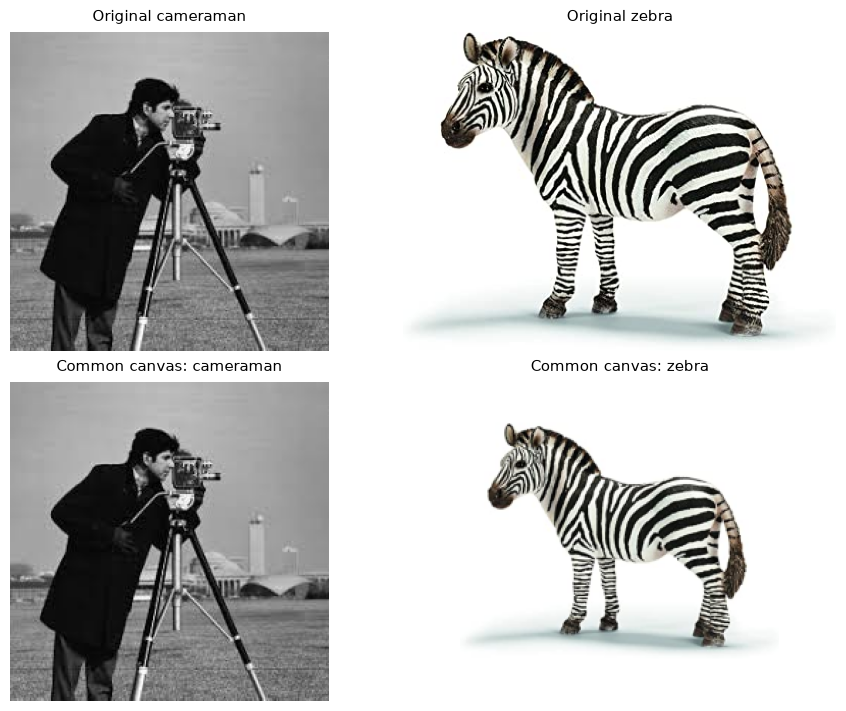

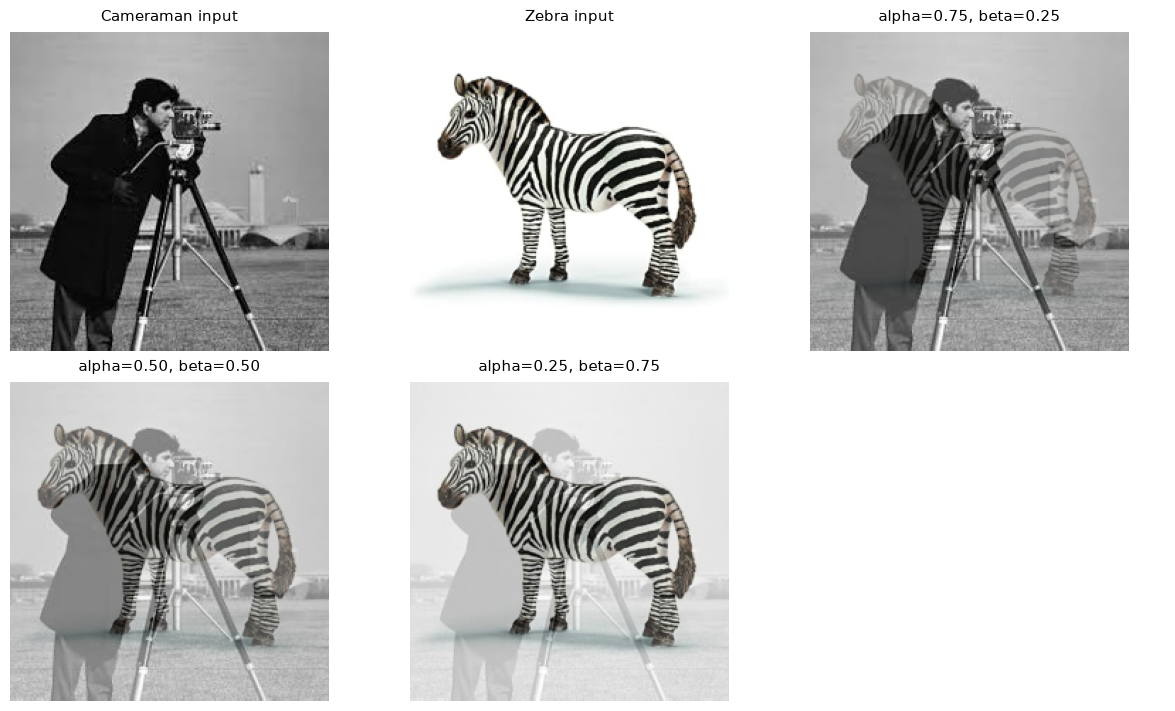

Zebra resized to 225 x 166; white padding top/bottom: 29/30.
Three weighted arithmetic checks: PASS.


In [3]:
cameraman, zebra = images['cameraman.jpg'], images['zebra.png']
print('Original HWC:', cameraman.shape, zebra.shape)
target_h, target_w = cameraman.shape[:2]
scale = min(target_w / zebra.shape[1], target_h / zebra.shape[0])
new_w, new_h = round(zebra.shape[1] * scale), round(zebra.shape[0] * scale)
zebra_resized = cv2.resize(zebra, (new_w, new_h), interpolation=cv2.INTER_AREA)
top, left = (target_h - new_h) // 2, (target_w - new_w) // 2
zebra_aligned = cv2.copyMakeBorder(zebra_resized, top, target_h - new_h - top,
                                  left, target_w - new_w - left,
                                  cv2.BORDER_CONSTANT, value=(255, 255, 255))
cameraman_aligned = cameraman.copy()
assert cameraman_aligned.shape == zebra_aligned.shape == (225, 225, 3)
save_image(2, 'original_cameraman', cameraman)
save_image(2, 'original_zebra', zebra)
save_image(2, 'resized_cameraman', cameraman_aligned)
save_image(2, 'resized_zebra', zebra_aligned)
blend_panels = []
blend_metrics = []
blends = []
for alpha, beta, name in [(0.75, 0.25, 'first_dominant'), (0.5, 0.5, 'equal'),
                          (0.25, 0.75, 'second_dominant')]:
    assert alpha + beta == 1
    blended = cv2.addWeighted(cameraman_aligned, alpha, zebra_aligned, beta, 0)
    expected = np.clip(np.rint(alpha * cameraman_aligned.astype(np.float64) +
                               beta * zebra_aligned.astype(np.float64)), 0, 255).astype(np.uint8)
    error = np.abs(blended.astype(np.int16) - expected.astype(np.int16))
    assert error.max() <= 1  # Allow a one-level implementation rounding difference.
    assert blended.dtype == np.uint8 and blended.shape == cameraman_aligned.shape
    assert not np.array_equal(blended, cameraman_aligned)
    assert not np.array_equal(blended, zebra_aligned)
    save_image(2, f'blend_{name}', blended)
    blends.append(blended)
    blend_panels.append((f'alpha={alpha:.2f}, beta={beta:.2f}', blended))
    blend_metrics.append({'alpha': alpha, 'beta': beta, 'max_rounding_error': int(error.max())})
assert not np.array_equal(blends[0], blends[1]) and not np.array_equal(blends[1], blends[2])
metrics['task2'] = {'resized_zebra_WH': [new_w, new_h], 'padding_TBLR':
                    [top, target_h - new_h - top, left, target_w - new_w - left],
                    'experiments': blend_metrics}
show_grid(2, 'input_comparison', [('Original cameraman', cameraman), ('Original zebra', zebra),
                              ('Common canvas: cameraman', cameraman_aligned),
                              ('Common canvas: zebra', zebra_aligned)], columns=2, width=9)
show_grid(2, 'comparison', [('Cameraman input', cameraman_aligned), ('Zebra input', zebra_aligned),
                          *blend_panels], columns=3, width=12)
checks['task2'] = 'PASS'
print(f'Zebra resized to {new_w} x {new_h}; white padding top/bottom: {top}/{target_h-new_h-top}.')
print('Three weighted arithmetic checks: PASS.')

The three figures have distinct appearances. At **alpha=0.75, beta=0.25**, the cameraman, tripod, and horizon remain dominant and the zebra looks like a faint second exposure. At **0.50, 0.50**, the zebra stripes and cameraman silhouette have similar strength, so neither scene reads as a clean foreground. At **0.25, 0.75**, the zebra becomes the clearest subject and the cameraman is pale behind it.

The background also changes, not only the two subjects. Most of the zebra image is white, so increasing beta blends high intensity values into the entire cameraman scene and makes the result brighter. The ghostly look comes from superimposing two semi-weighted subjects at the same coordinates while their backgrounds are mixed as well. A cleaner composite would require removing the zebra background and placing its foreground deliberately, but that would be different from the requested whole-image weighted blend. The independent arithmetic check below confirms that all three saved results match the rounded per-pixel equations exactly.

## Task 3 - Artistic Vignette Filtering

I want to keep attention on the rover and the nearby terrain while progressively darkening the frame edges. I start with a single-channel black mask and draw a filled white circle at the image centre. In a multiplication mask, white corresponds to a weight near 1 and black to a weight near 0. If I multiplied the image by this hard circle directly, the brightness would stop abruptly at the circumference and leave an obvious circular cut-out.

I therefore blur the circle with a Gaussian filter. The radius is **0.47 x min(height, width) = 226 pixels**, and the Gaussian sigma is **0.19 x min(height, width) = 91.2 pixels** with a 549 x 549 kernel. Blurring replaces the two mask values with a continuous range; after normalization, the brightest centre is 1 and the surrounding weights approach 0. I calculate

**output(y,x,c) = round(input(y,x,c) x weight(y,x))**

for each BGR channel. A weight of 1 preserves a pixel, 0.5 halves its intensity, and a value close to 0 makes it almost black. I keep the mask in floating point during multiplication so those intermediate weights are not lost.

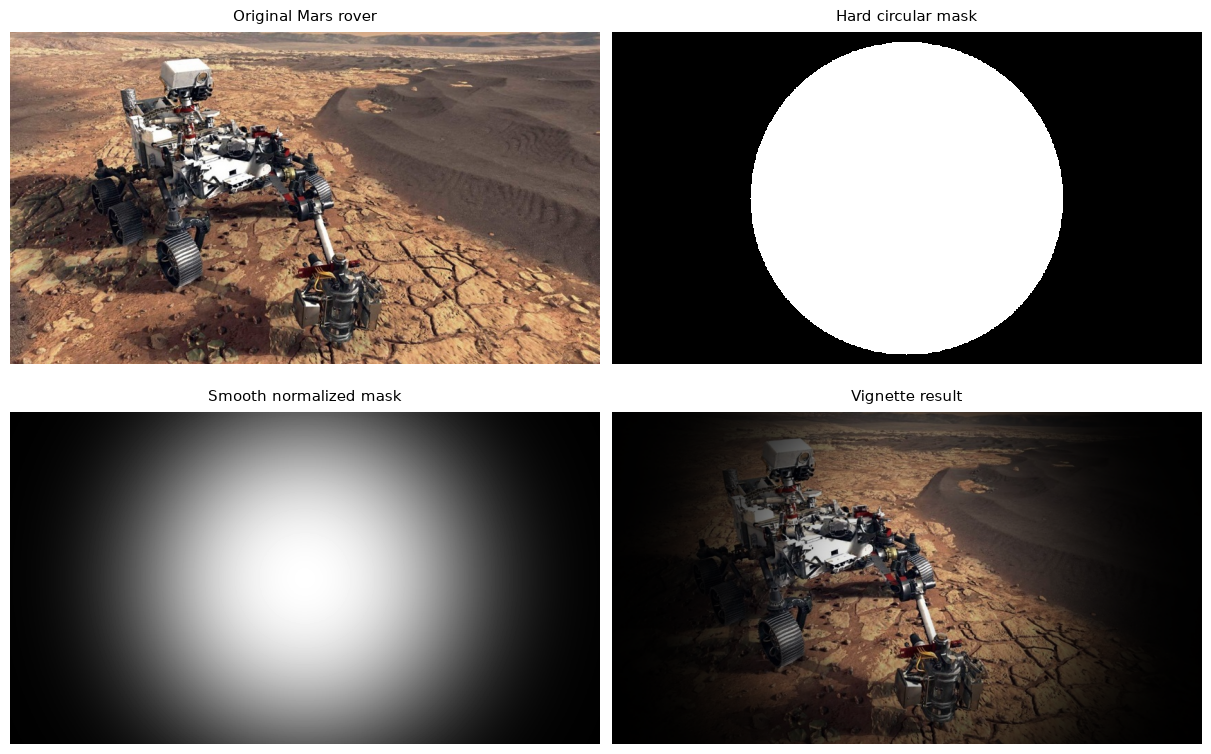

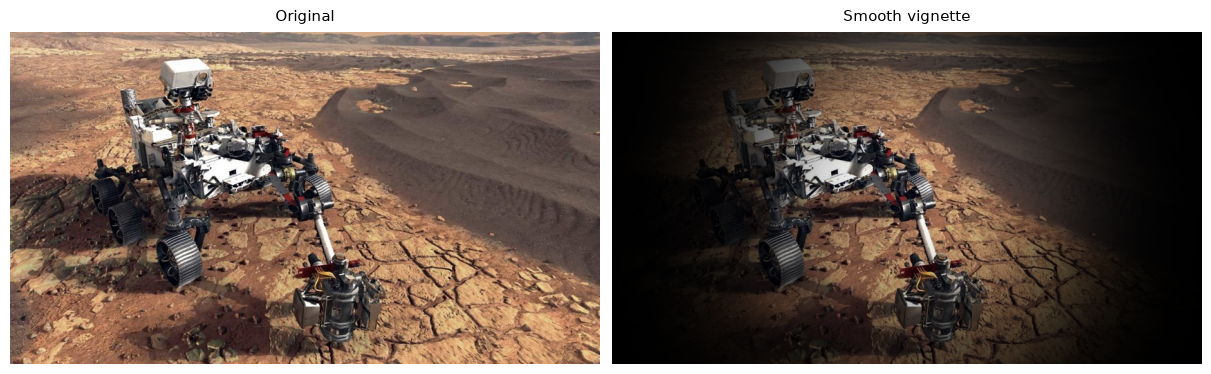

{
  "radius": 226,
  "sigma": 91.2,
  "kernel_size": 549,
  "center_before_mean": 106.88298286604362,
  "center_after_mean": 101.00338785046729,
  "corner_before_mean": 138.67205882352943,
  "corner_after_mean": 0.9096813725490196,
  "max_adjacent_weight_step": 0.004358887672424316,
  "center_weight": 1.0
}


In [4]:
rover = images['marsrover.png']
height, width = rover.shape[:2]
circular_mask = np.zeros((height, width), dtype=np.uint8)
center = (width // 2, height // 2)
radius = round(0.47 * min(height, width))
sigma = 0.19 * min(height, width)
kernel_size = 2 * int(np.ceil(3 * sigma)) + 1
cv2.circle(circular_mask, center, radius, 255, thickness=-1)
# Blur in float to avoid quantizing the soft weights before multiplication.
blurred_float = cv2.GaussianBlur(circular_mask.astype(np.float32),
                               (kernel_size, kernel_size), sigmaX=sigma, sigmaY=sigma,
                               borderType=cv2.BORDER_CONSTANT)
weights = blurred_float / blurred_float.max()
blurred_display = np.clip(np.rint(weights * 255), 0, 255).astype(np.uint8)
vignette = np.clip(np.rint(rover.astype(np.float32) * weights[..., None]), 0, 255).astype(np.uint8)

assert circular_mask.shape == weights.shape == rover.shape[:2]
assert set(np.unique(circular_mask)) == {0, 255}
assert np.isfinite(weights).all() and weights.min() >= 0 and weights.max() <= 1
assert vignette.dtype == np.uint8 and vignette.shape == rover.shape
assert np.all(vignette <= rover)
assert np.array_equal(vignette[center[1], center[0]], rover[center[1], center[0]])
# Compare the center quarter with the four 10%-sized corner patches.
center_slice = (slice(3 * height // 8, 5 * height // 8), slice(3 * width // 8, 5 * width // 8))
ph, pw = height // 10, width // 10
def corner_values(array):
    return np.concatenate([array[:ph, :pw].ravel(), array[:ph, -pw:].ravel(),
                           array[-ph:, :pw].ravel(), array[-ph:, -pw:].ravel()])
before_gray = cv2.cvtColor(rover, cv2.COLOR_BGR2GRAY)
after_gray = cv2.cvtColor(vignette, cv2.COLOR_BGR2GRAY)
center_mean = float(after_gray[center_slice].mean())
corner_mean = float(corner_values(after_gray).mean())
assert corner_mean < center_mean
assert corner_values(after_gray).mean() < corner_values(before_gray).mean()
assert weights[center_slice].mean() > corner_values(weights).mean()
max_step = max(float(np.abs(np.diff(weights, axis=0)).max()),
               float(np.abs(np.diff(weights, axis=1)).max()))
assert max_step < 0.02  # No abrupt one-pixel circular boundary.
metrics['task3'] = {'radius': radius, 'sigma': sigma, 'kernel_size': kernel_size,
                    'center_before_mean': float(before_gray[center_slice].mean()),
                    'center_after_mean': center_mean,
                    'corner_before_mean': float(corner_values(before_gray).mean()),
                    'corner_after_mean': corner_mean, 'max_adjacent_weight_step': max_step,
                    'center_weight': float(weights[center[1], center[0]])}
for name, image in [('original', rover), ('circular_mask', circular_mask),
                    ('blurred_mask', blurred_display), ('vignette', vignette)]:
    save_image(3, name, image)
show_grid(3, 'stages', [('Original Mars rover', rover), ('Hard circular mask', circular_mask),
                      ('Smooth normalized mask', blurred_display), ('Vignette result', vignette)],
          columns=2, width=12, row_height=3.8)
show_grid(3, 'comparison', [('Original', rover), ('Smooth vignette', vignette)],
          columns=2, width=12, row_height=4)
checks['task3'] = 'PASS'
print(json.dumps(metrics['task3'], indent=2))

The hard-mask panel explains where the centre region comes from, while the smooth-mask panel shows why no sharp circle appears in the final image. The centre pixel is unchanged. The mean grayscale value of the centre quarter changes only from **106.88 to 101.00**, whereas the four corner patches fall from **138.67 to 0.91**. Visually, the rover body, wheels, arm, and central rock texture remain readable, while the corners and distant side terrain recede. Applying the same weight to all three channels changes brightness without deliberately shifting hue, apart from small `uint8` rounding effects.

The result depends on the mask parameters. A smaller radius would darken more of the rover; a larger radius would retain more of the original frame. Increasing sigma would spread the transition farther, while a smaller sigma would make the circle boundary more noticeable. Introducing a nonzero minimum weight would preserve more corner detail. I did not add such a floor here because the near-black corners give the strong artistic framing requested, while the central subject still retains sufficient detail.

## Task 4 - Channel Swapping (Surreal Colours)

A colour pixel has three intensity values. OpenCV stores them as **blue, green, red**, so splitting an image exposes three two-dimensional intensity planes. Merging those same planes as `(B,G,R)` reconstructs the source exactly. Merging them in another order does not move any pixel or invent a new value; it changes which display colour receives each original plane.

Every tuple below lists the source planes assigned to **(output blue, output green, output red)**:

| Arrangement | Output B | Output G | Output R |
|---|---|---|---|
| Original (B,G,R) | B | G | R |
| Swap 1 (R,G,B) | R | G | B |
| Swap 2 (B,R,G) | B | R | G |
| Swap 3 (G,B,R) | G | B | R |

For example, `(B,R,G)` keeps the blue plane in place, displays original red values as green, and displays original green values as red. A grayscale pixel has B=G=R, so permuting three equal numbers cannot change it. This predicts that the zebra's black stripes and white background will be far less affected than its tinted coat, muzzle, tail, and shadow.

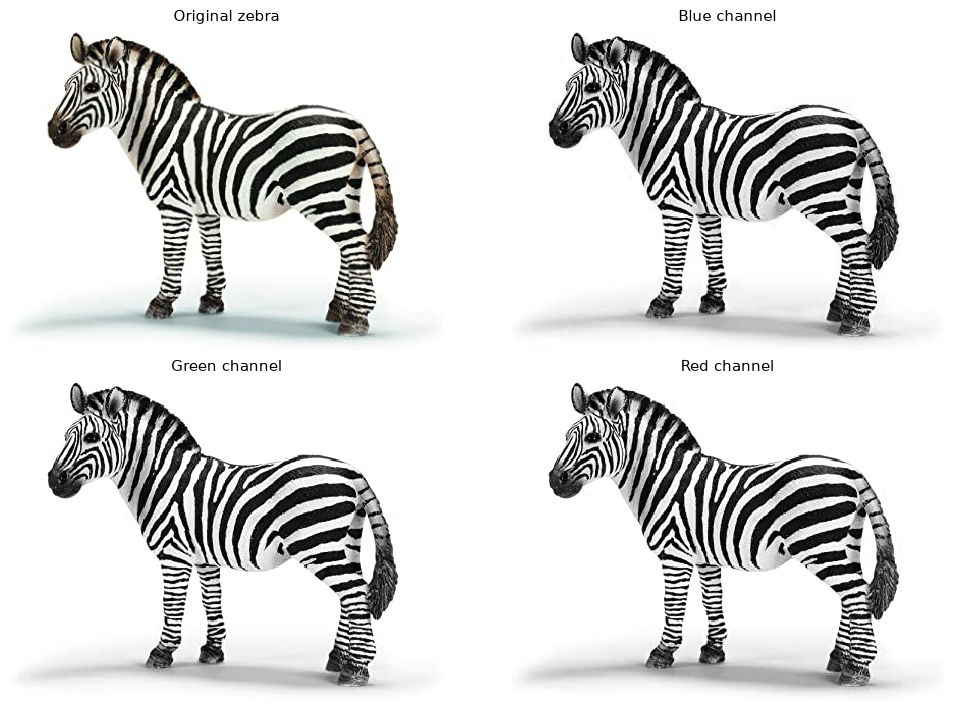

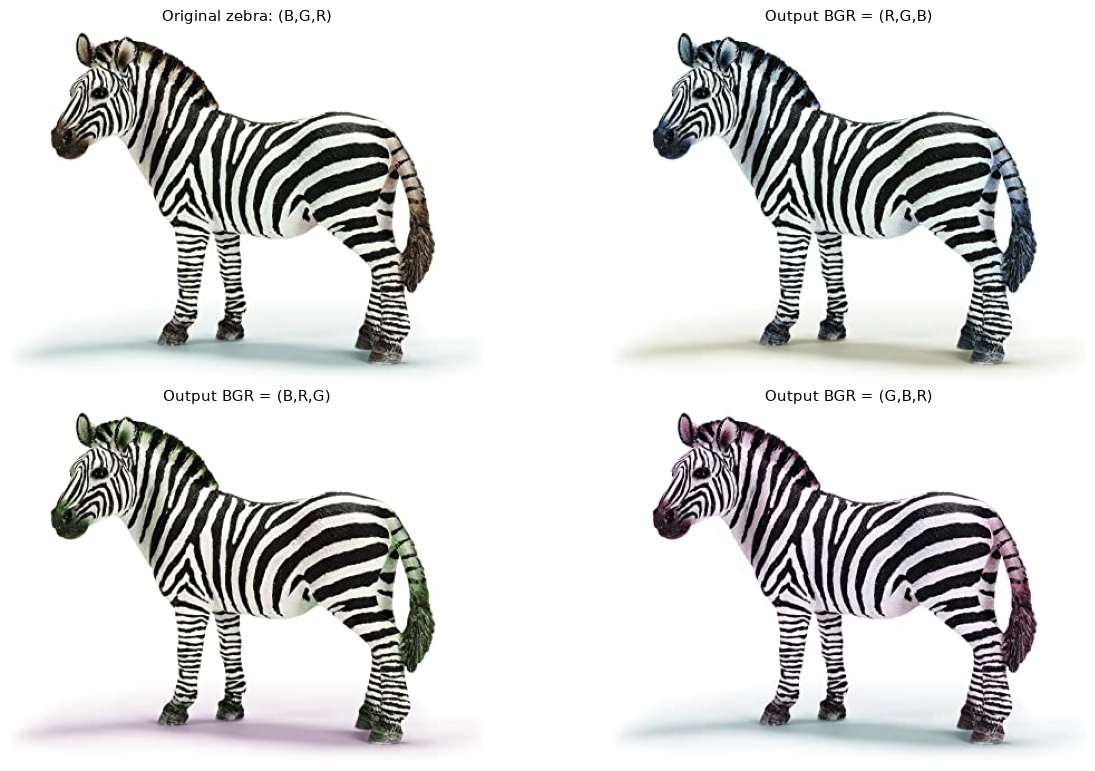

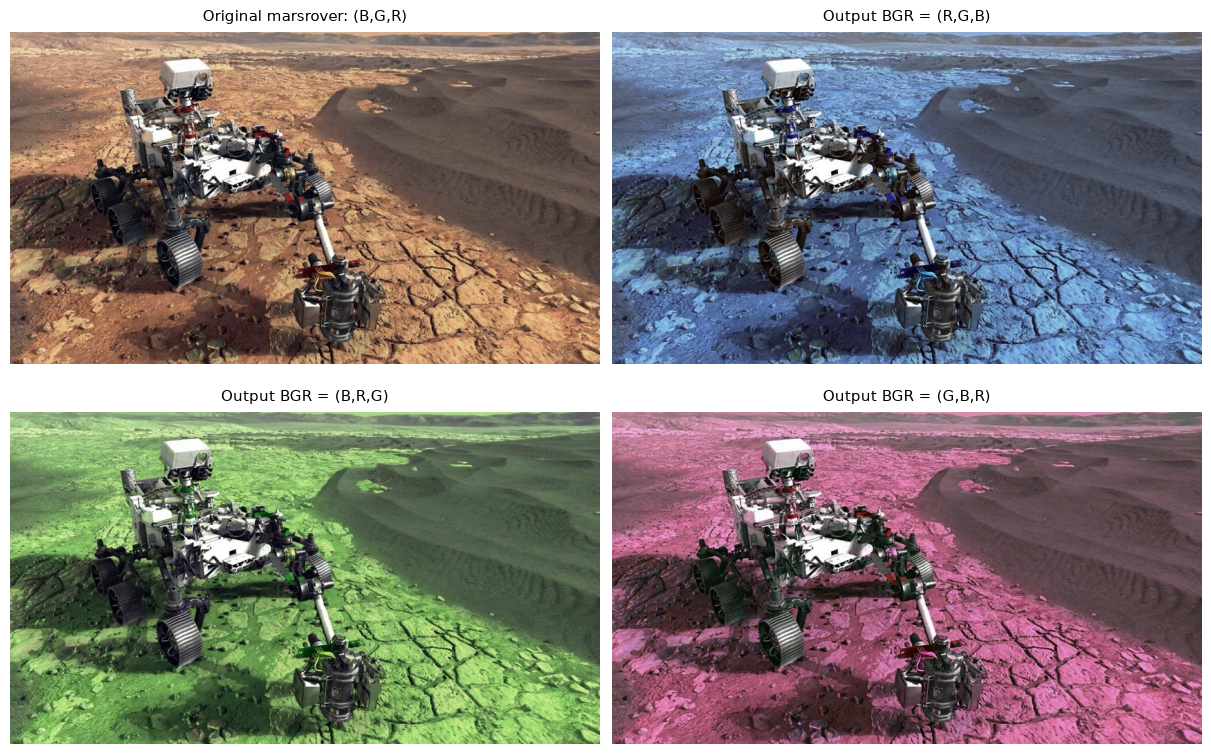

| Image | Output BGR tuple | MAE (0-255 levels) | Max difference | Changed pixels |
|---|---|---:|---:|---:|
| zebra | (R,G,B) | 2.356 | 64 | 51.10% |
| zebra | (B,R,G) | 1.408 | 34 | 45.17% |
| zebra | (G,B,R) | 1.714 | 35 | 50.15% |
| marsrover | (R,G,B) | 29.796 | 156 | 99.39% |
| marsrover | (B,R,G) | 18.264 | 126 | 98.11% |
| marsrover | (G,B,R) | 11.737 | 95 | 97.85% |

Reconstruction, all channel assignments, and neutral-pixel invariance: PASS.


In [5]:
z_blue, z_green, z_red = cv2.split(zebra)
reconstructed = cv2.merge((z_blue, z_green, z_red))
assert np.array_equal(reconstructed, zebra)
for name, image in [('original', zebra), ('blue_channel', z_blue),
                    ('green_channel', z_green), ('red_channel', z_red),
                    ('reconstructed_bgr', reconstructed)]:
    save_image(4, name, image)
show_grid(4, 'channels', [('Original zebra', zebra), ('Blue channel', z_blue),
                        ('Green channel', z_green), ('Red channel', z_red)], columns=2, width=10)

arrangements = [('swap1_RGB', (2, 1, 0), '(R,G,B)'),
                ('swap2_BRG', (0, 2, 1), '(B,R,G)'),
                ('swap3_GBR', (1, 0, 2), '(G,B,R)')]
swap_metrics = []
for source_name, source in [('zebra', zebra), ('marsrover', rover)]:
    channels = cv2.split(source)
    neutral = (source[..., 0] == source[..., 1]) & (source[..., 1] == source[..., 2])
    panels = [(f'Original {source_name}: (B,G,R)', source)]
    for filename, order, label in arrangements:
        swapped = cv2.merge(tuple(channels[index] for index in order))
        assert swapped.dtype == source.dtype and swapped.shape == source.shape
        for out_channel, in_channel in enumerate(order):
            assert np.array_equal(swapped[..., out_channel], source[..., in_channel])
        assert np.array_equal(swapped[neutral], source[neutral])
        difference = np.abs(swapped.astype(np.int16) - source.astype(np.int16))
        row = {'source': source_name, 'BGR_tuple': label,
               'MAE': float(difference.mean()), 'max_difference': int(difference.max()),
               'changed_pixel_percent': float(100 * np.any(difference != 0, axis=2).mean())}
        swap_metrics.append(row)
        save_image(4, f'{source_name}_{filename}', swapped)
        panels.append((f'Output BGR = {label}', swapped))
    show_grid(4, 'comparison' if source_name == 'zebra' else 'supplementary_marsrover',
              panels, columns=2, width=12, row_height=3.8)
metrics['task4'] = {'experiments': swap_metrics,
                    'neutral_zebra_percent': float(100 * ((z_blue == z_green) & (z_green == z_red)).mean())}
display(Markdown('| Image | Output BGR tuple | MAE (0-255 levels) | Max difference | Changed pixels |\n'
                 '|---|---|---:|---:|---:|\n' + '\n'.join(
    f'| {row["source"]} | {row["BGR_tuple"]} | {row["MAE"]:.3f} | {row["max_difference"]} | {row["changed_pixel_percent"]:.2f}% |'
    for row in swap_metrics)))
checks['task4'] = 'PASS'
print('Reconstruction, all channel assignments, and neutral-pixel invariance: PASS.')

The zebra results match that prediction. The cooler, greener, or magenta tint is easiest to see around the ears and muzzle, along the tail, and in the pale ground shadow. The black stripes, white coat, and background remain almost unchanged. Exactly **46.47%** of the zebra pixels have B=G=R and are invariant under every permutation. Although roughly 45-51% of pixels change in the three outputs, their mean absolute channel changes are only **2.356, 1.408, and 1.714** levels out of 255. A high changed-pixel count therefore does not imply a strong visible recolouring when the original channels differ by only a few levels.

I use the Mars rover as a supplementary comparison with exactly the same channel assignments. Its orange-brown terrain contains much more red than blue, so the permutations turn the scene strongly blue, green, or magenta. The corresponding mean changes are **29.796, 18.264, and 11.737**, much larger than for the zebra. This comparison shows that channel swapping changes colour interpretation while preserving spatial structure, and that the visual strength of the result depends on how unequal the source channels already are.

## Final checks

The checks below connect the displayed results to the arrays that produced them. They verify the complementary mask composition, the three weighted-addition equations, the vignette bounds and brightness change, and every requested channel assignment. They also reopen each saved PNG and confirm that the supplied input arrays and source bytes were not modified. These checks support the observations above without replacing the visual interpretation of the figures.

In [6]:
for name, image in images.items():
    assert np.array_equal(image, original_copies[name]), f'Input array modified: {name}'
    assert hashlib.sha256((ROOT / 'images' / name).read_bytes()).hexdigest() == input_info[name]['sha256']
for path in RESULTS.rglob('*.png'):
    reloaded = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    assert reloaded is not None and reloaded.dtype == np.uint8 and reloaded.size > 0
assert checks == {f'task{i}': 'PASS' for i in range(1, 5)}
verification = {'checks': checks, 'inputs': input_info, 'metrics': metrics,
                'saved_arrays': saved_arrays,
                'png_count': len(list(RESULTS.rglob('*.png'))),
                'versions': {'python': sys.version.split()[0], 'opencv': cv2.__version__,
                             'numpy': np.__version__, 'matplotlib': matplotlib.__version__}}
(RESULTS / 'verification.json').write_text(json.dumps(verification, indent=2), encoding='utf-8')
print(json.dumps(checks, indent=2))
print(f'Verified {verification["png_count"]} saved PNG images and figures; all six inputs unchanged.')

{
  "task1": "PASS",
  "task2": "PASS",
  "task3": "PASS",
  "task4": "PASS"
}
Verified 38 saved PNG images and figures; all six inputs unchanged.


## Conclusion

The four tasks gave me different ways to control an image at pixel level. In Task 1, complementary masks combine selected original colour with grayscale exactly, but the patchy apples show that a colour threshold has no understanding of object boundaries. In Task 2, normalized weights control the contribution of two complete images, including their backgrounds, which explains both the ghostly subjects and the brightening caused by the zebra's white canvas. In Task 3, Gaussian smoothing turns a binary circle into continuous multiplication weights, preserving central detail while gradually suppressing the edges. In Task 4, channel order changes the meaning of the stored values; neutral pixels remain stable, while a strongly coloured source such as the Mars scene changes dramatically.

The main trade-off across the lab is that simple array operations are predictable and easy to verify, but their visual result depends strongly on the content of the source images and the chosen parameters. The executed notebook and the report use the same thresholds, blend weights, vignette settings, permutations, and generated figures.